# 04 · Benchmark: classical OLS regression vs Meridian

This notebook is a transparent sanity check for the Meridian model in notebook 03. Every forecast below is scored on the **same hold-outs** that Meridian used:

| Model | Inputs |
|---|---|
| Naive | weekday mean of the training period |
| OLS-1 | the 7 raw channel costs only (the literal "sales from budget" regression) |
| OLS-2 | Meridian's inputs: digital costs, catalog in-home adstock and all controls |
| **Meridian** | Bayesian regression with adstock, Hill saturation and priors (notebook 03) |

In [1]:
import json
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm

from tchibo_mmm import data, evaluate, features
from tchibo_mmm import mmm as M
from tchibo_mmm.plotting import CHANNEL_COLORS, INK_2, MUTED, save, use_style

warnings.filterwarnings("ignore")
use_style()
pd.set_option("display.float_format", "{:,.3f}".format)

wide = data.build_wide_table(data.load_raw())
y = wide["total_sales"]
idx = wide.index
paid_cols = [f"cost_{data.slug(c)}" for c in data.PAID_CHANNELS]
digital_cols = [c for c in paid_cols if c != "cost_catalog"]

cat_inhome = pd.Series(
    np.convolve(features.shift_spend(wide["cost_catalog"], 2), features.geometric_decay_weights(0.8, 21))[: len(idx)],
    index=idx, name="catalog_inhome_adstock")
controls = features.calendar_controls(idx).join(features.seasonality_controls(idx))
X_sets = {
    "OLS-1 raw costs": wide[paid_cols],
    "OLS-2 Meridian inputs": wide[digital_cols].join(cat_inhome).join(controls),
}


def ols_forecast(X, train_end, test_start, test_end):
    tr = idx <= pd.Timestamp(train_end)
    te = (idx >= pd.Timestamp(test_start)) & (idx <= pd.Timestamp(test_end))
    fit = sm.OLS(y[tr], sm.add_constant(X[tr], has_constant="add")).fit()
    return pd.Series(fit.predict(sm.add_constant(X[te], has_constant="add")), index=idx[te])


def weekday_mean_forecast(train_end, test_start, test_end):
    tr = idx <= pd.Timestamp(train_end)
    te = (idx >= pd.Timestamp(test_start)) & (idx <= pd.Timestamp(test_end))
    prof = y[tr].groupby(idx[tr].dayofweek).mean()
    return pd.Series(prof.reindex(idx[te].dayofweek).values, index=idx[te])

## 1. Same hold-outs as Meridian

In [2]:
windows = {"Q4 2024 (train to Sep)": ("2024-09-30", "2024-10-01", "2025-01-01"),
           "Q3 2024 (train to Jun)": ("2024-06-30", "2024-07-01", "2024-09-30")}
mer = json.loads((M.OUTPUT_DIR / "meridian_metrics.json").read_text())
mer_by_window = {"Q4 2024 (train to Sep)": mer["holdout_q4_2024"], "Q3 2024 (train to Jun)": mer["holdout_q3_2024_forward"]}

rows = []
for wname, (tr_end, te_start, te_end) in windows.items():
    preds = {"Naive weekday mean": weekday_mean_forecast(tr_end, te_start, te_end)}
    preds |= {name: ols_forecast(X, tr_end, te_start, te_end) for name, X in X_sets.items()}
    for name, p in preds.items():
        rows.append({"hold-out": wname, "model": name, **evaluate.metrics(y.loc[p.index], p)})
    rows.append({"hold-out": wname, "model": "Meridian MMM", **mer_by_window[wname]})
comparison = pd.DataFrame(rows).set_index(["hold-out", "model"])
comparison[["MAE", "MAE/mean", "RMSE", "R2", "MAPE"]].style.format(
    {"MAE": "{:,.0f}", "RMSE": "{:,.0f}", "MAE/mean": "{:.1%}", "MAPE": "{:.1%}", "R2": "{:.3f}"})

## 2. Walk-forward cross-validation for the OLS models

Meridian is too slow to refit 8 times here (minutes per fit), so walk-forward cross-validation is shown for the OLS models only. Setup: 8 folds of 6 weeks each, from 2024-01-15, with an expanding training window.

In [3]:
starts = pd.date_range("2024-01-15", periods=8, freq="42D")
cv = {}
for name in ["Naive weekday mean", *X_sets]:
    scores = []
    for s in starts:
        e = min(s + pd.Timedelta(days=41), idx[-1])
        tr_end = s - pd.Timedelta(days=1)
        p = (weekday_mean_forecast(tr_end, s, e) if name.startswith("Naive")
             else ols_forecast(X_sets[name], tr_end, s, e))
        scores.append(evaluate.metrics(y.loc[p.index], p)["MAE/mean"])
    cv[name] = scores
cv = pd.DataFrame(cv, index=[s.strftime("%Y-%m-%d") for s in starts]).T
cv["mean"], cv["worst"] = cv.mean(axis=1), cv.max(axis=1)
cv.style.format("{:.1%}")

,2024-01-15,2024-02-26,2024-04-08,2024-05-20,2024-07-01,2024-08-12,2024-09-23,2024-11-04,mean,worst
Naive weekday mean,16.9%,17.3%,14.5%,14.9%,12.4%,22.5%,28.4%,37.6%,20.5%,37.6%
OLS-1 raw costs,11.6%,26.9%,20.2%,16.7%,10.6%,16.9%,6.1%,11.2%,15.0%,26.9%
OLS-2 Meridian inputs,10.3%,9.4%,7.3%,9.2%,8.5%,15.5%,9.1%,6.7%,9.5%,15.5%


## 3. Summary chart

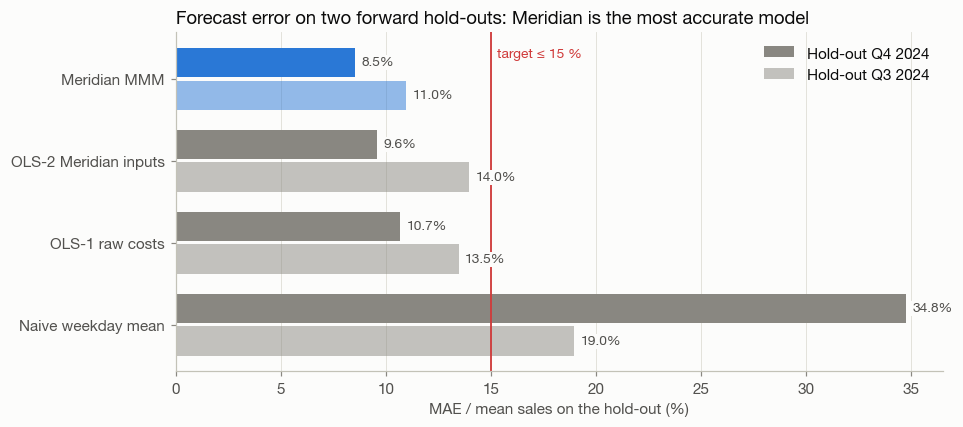

In [4]:
q4 = comparison.xs("Q4 2024 (train to Sep)", level="hold-out")["MAE/mean"]
q3 = comparison.xs("Q3 2024 (train to Jun)", level="hold-out")["MAE/mean"]
models = list(q4.index)
fig, ax = plt.subplots(figsize=(9, 4))
pos = np.arange(len(models))
ax.barh(pos + 0.2, q4.values * 100, height=0.36, color=[CHANNEL_COLORS["SEA"] if m == "Meridian MMM" else MUTED
                                                         for m in models], label="Hold-out Q4 2024")
ax.barh(pos - 0.2, q3.values * 100, height=0.36, color=[CHANNEL_COLORS["SEA"] if m == "Meridian MMM" else MUTED
                                                         for m in models], alpha=0.5, label="Hold-out Q3 2024")
ax.axvline(15, color="#d03b3b", lw=1.2, zorder=1)
label_box = {"facecolor": "#fcfcfb", "edgecolor": "none", "pad": 1}
for i, m in enumerate(models):
    ax.text(q4[m] * 100 + 0.3, i + 0.2, f"{q4[m]:.1%}", va="center", fontsize=9, color=INK_2, bbox=label_box, zorder=3)
    ax.text(q3[m] * 100 + 0.3, i - 0.2, f"{q3[m]:.1%}", va="center", fontsize=9, color=INK_2, bbox=label_box, zorder=3)
ax.annotate("target ≤ 15 %", (15, len(models) - 0.7), xytext=(4, 0), textcoords="offset points", fontsize=9, color="#d03b3b",
            va="center")
ax.set_yticks(pos, models)
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.set_xlabel("MAE / mean sales on the hold-out (%)")
ax.set_title("Forecast error on two forward hold-outs: Meridian is the most accurate model")
ax.legend(loc="upper right")
save(fig, "04_model_comparison");

## 4. Takeaways

- **Naive forecasts fail the target** (19–35 % MAE / mean). All budget-based regressions pass it on both forward hold-outs.
- **Raw costs alone (OLS-1) are unreliable.**
  - Their hold-out results look acceptable, but walk-forward folds swing up to 27 %.
  - Same-day costs miss the catalog's delay and the seasonality.
- **OLS-2 (Meridian's inputs) is robust:** 9.5 % on average across 8 walk-forward folds, 15.5 % in the worst fold.
- **Meridian is the most accurate model on both hold-outs:** 8.5 % vs 9.6 % for OLS-2 in Q4, and 11.0 % vs 14.0 % in Q3.
  - The same inputs gain from learned carry-over and saturation per channel.
  - On top, Meridian gives what OLS cannot: credible intervals, ROI and response curves, and budget optimisation.
  - That is why it is the main model.